# European Covered Bond Spreads: Drivers and Forecasts with Machine Learning

Covered bonds are the main long-term funding of European banks and a large high-grade asset class for central banks, development banks and insurers. Their spreads over government bonds move with the issuer, the country, the legal framework and, for almost a decade, the ECB's own buying. This notebook builds ten years of bond-level spreads and asks what explains them and whether their next move can be forecast.

**What it does.** It builds a ten-year monthly panel of euro covered bonds from the month-end holdings of the iShares € Covered Bond ETF: about 900 bonds a month and 116,000 bond-months since 2016, from 25 countries and around 150 issuers. Each bond's **z-spread over the ECB AAA euro-area government curve** is computed from its price, coupon and maturity.

The notebook then asks two questions:

- **What explains the cross-section of spreads?** Country, issuer, maturity, coupon and the macro-financial state, measured with gradient boosting and SHAP.
- **Can next quarter's spread change be forecast?** The market-wide move and each bond's relative move are forecast separately, walk-forward, against a random walk and against mean reversion to the bond's peer group.

**Data.** iShares € Covered Bond UCITS ETF holdings (monthly, February 2016 to September 2026), and from the ECB Statistical Data Warehouse the Svensson parameters of the AAA euro-area government yield curve, ten-year government bond yields by country, the deposit facility rate and the Composite Indicator of Systemic Stress (CISS).

**Methods.** Z-spread bootstrapping, LightGBM with issuer-grouped cross-validation and SHAP, and walk-forward forecasts of the common and the relative spread move (ridge, LightGBM, information coefficients, Diebold–Mariano tests). Conformalised quantile regression gives spread-risk bands.

**Key output.** Spread history by country through the end of the ECB covered bond purchase programme, the drivers of spreads with their marginal effects, and forecast skill against the benchmarks.

## 1. Why covered bond spreads matter

Covered bonds are senior bank bonds with **double recourse**: to the issuing bank and, if it fails, to a ring-fenced cover pool of mortgages or public-sector loans. They are the main long-term funding instrument of European banks (over €2.5 trn outstanding) and one of the largest high-grade asset classes for central banks, supranationals, development banks and insurers. Their spread over government bonds prices three things:
- **issuer and sovereign credit risk:** the bank's rating and the country it sits in;
- **the legal framework and cover-pool quality:** strong frameworks (German Pfandbriefe, Danish mortgage bonds) trade tighter;
- **liquidity and supply/demand:** the ECB bought covered bonds under CBPP3 from October 2014 and stopped reinvesting in July 2023, which removed a buyer just as supply and rates jumped.

For an investor or a treasury that holds them as high-quality liquid assets, spreads drive mark-to-market and haircuts. For an issuer, they set funding costs.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
import shap
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 23
FUND_URL = (
    "https://www.ishares.com/ch/professionals/en/products/251842/ishares-covered-bond-ucits-etf/"
    "1495092304805.ajax?fileType=csv&fileName=ICOV_holdings&dataType=fund&asOfDate={}"
)
ECB = "https://data-api.ecb.europa.eu/service/data/{}?format=csvdata&startPeriod=2015-06-01"
START, END = "2016-01-31", "2026-09-30"
HORIZON = 3  # forecast horizon in months
EA_CODES = {
    "Austria": "AT",
    "Belgium": "BE",
    "Finland": "FI",
    "France": "FR",
    "Germany": "DE",
    "Ireland": "IE",
    "Italy": "IT",
    "Netherlands": "NL",
    "Portugal": "PT",
    "Spain": "ES",
    "Slovak Republic": "SK",
    "Slovenia": "SI",
    "Estonia": "EE",
    "Lithuania": "LT",
    "Latvia": "LV",
    "Luxembourg": "LU",
    "Cyprus": "CY",
    "Greece": "GR",
}

print(
    f"lightgbm {lgb.__version__} · shap {shap.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · shap 0.54.1 · run on 2026-10-20


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Data

**Holdings.** iShares publishes the full holdings file of each fund for any past business day. For every month-end from February 2016, the notebook downloads it, stepping back up to four business days if the month-end file is missing. The resulting files are cached in `data/` and reused afterwards.

Each row is one bond: issuer name, country, clean price, coupon, maturity, duration and the fund's par holding. The fund tracks the Markit iBoxx EUR Covered index, so this is close to the investable euro covered bond universe. Bonds have no ISIN in the file, so a bond is identified by its name, coupon and maturity.

**ECB data.**
- **Yield curve.** The daily Svensson parameters of the AAA euro-area government yield curve give a zero rate at any maturity.
- **Country yields.** Monthly ten-year government bond yields for euro-area countries are matched to each bond's country. Non-euro issuers (Norway, Canada, Australia, the UK…) get a missing value, which LightGBM handles natively.
- **Monetary policy and stress.** The ECB deposit facility rate and the CISS systemic stress index.

In [3]:
def fetch_month(m):
    """
    One month-end holdings file (steps back up to 4 business days if that date
    has no file).
    """
    for back in range(5):
        d = (m - pd.tseries.offsets.BDay(back)).strftime("%Y%m%d")
        t = requests.get(
            FUND_URL.format(d), headers=BROWSER_HEADERS, timeout=60
        ).text
        if t.count("\n") > 50:
            lines = t.splitlines()
            df = pd.read_csv(
                io.StringIO("\n".join(lines[2:])), thousands="’", dtype=str
            )
            df["asof"] = pd.to_datetime(
                lines[0].split('"')[1].replace("Sept", "Sep"),
                format="%d/%b/%Y",
            )
            return df
        time.sleep(0.3)
    return pd.DataFrame()


def fetch_holdings():
    return pd.concat(
        [fetch_month(m) for m in pd.date_range(START, END, freq="BME")],
        ignore_index=True,
    )


def ecb(key):
    d = pd.read_csv(
        io.StringIO(requests.get(ECB.format(key), timeout=120).text)
    )
    return d[["KEY", "TIME_PERIOD", "OBS_VALUE"]]


raw = cached("icov_holdings_monthly", fetch_holdings, max_age_hours=24 * 30)
yc = cached(
    "ecb_aaa_svensson",
    lambda: ecb(
        "YC/B.U2.EUR.4F.G_N_A.SV_C_YM.BETA0+BETA1+BETA2+BETA3+TAU1+TAU2"
    ),
    max_age_hours=24 * 7,
)
lty = cached(
    "ecb_10y_yields",
    lambda: ecb(
        "IRS/M."
        + "+".join(sorted(set(EA_CODES.values())))
        + ".L.L40.CI.0000.EUR.N.Z"
    ),
    max_age_hours=24 * 7,
)
dfr = cached(
    "ecb_dfr", lambda: ecb("FM/D.U2.EUR.4F.KR.DFR.LEV"), max_age_hours=24 * 7
)
ciss = cached(
    "ecb_ciss",
    lambda: ecb("CISS/D.U2.Z0Z.4F.EC.SS_CIN.IDX"),
    max_age_hours=24 * 7,
)

h = raw[raw["Asset Class"] == "Fixed Income"].copy()
num = lambda s: pd.to_numeric(
    s.astype(str).str.replace("’", "").str.replace(",", ""), errors="coerce"
)
h["price"], h["coupon"], h["duration"], h["par"] = (
    num(h["Price"]),
    num(h["Coupon (%)"]),
    num(h["Duration"]),
    num(h["Par Value"]),
)
h["maturity"] = pd.to_datetime(
    h["Maturity"].str.replace("Sept", "Sep"),
    format="%d/%b/%Y",
    errors="coerce",
)
h["issuer"] = (
    h["Name"]
    .str.upper()
    .str.replace(r"\s+(MTN|RegS|REGS|144A|EMTN)\b.*$", "", regex=True)
    .str.strip()
)
h["country"] = h["Location"]
h = h.dropna(subset=["price", "coupon", "maturity"])
h["T"] = (h["maturity"] - h["asof"]).dt.days / 365.25
h = h[(h["T"] > 0.25) & (h["price"].between(50, 160))]
h["bond_id"] = (
    h["issuer"]
    + "|"
    + h["coupon"].round(3).astype(str)
    + "|"
    + h["maturity"].dt.strftime("%Y-%m-%d")
)
h = h.drop_duplicates(["asof", "bond_id"])
print(
    f"{h['asof'].nunique()} month-ends {h['asof'].min():%Y-%m} →"
    f" {h['asof'].max():%Y-%m} · {len(h):,} bond-months ·"
    f" {h['bond_id'].nunique():,} bonds · {h['issuer'].nunique()} issuer names"
    f" · {h['country'].nunique()} countries"
)
h.groupby("country")["bond_id"].nunique().sort_values(ascending=False).head(
    12
).to_frame("distinct bonds")

122 month-ends 2016-02 → 2026-09 · 116,252 bond-months · 2,660 bonds · 362 issuer names · 33 countries


,distinct bonds
country,
Germany,596
France,473
Spain,157
Austria,155
Netherlands,147
Canada,146
Italy,142
Norway,134
United Kingdom,111


## 4. From prices to z-spreads over the AAA curve

The **z-spread** $z$ solves

$$P^{\text{dirty}} = \sum_k c\,\tau_k\,e^{-(r(t_k)+z)\,t_k} + 100\,e^{-(r(T)+z)\,T},$$

where:
- $r(t)$ is the AAA zero rate from the Svensson curve of the same day;
- coupons are annual (the euro covered bond convention);
- accrued interest is added to the clean price.

The equation is solved by vectorised Newton iterations for all 116,000 bond-months at once.

The spread over AAA is not a pure credit spread. It contains country risk as well (a Spanish cédula is priced off Spanish sovereign risk too) and a liquidity premium. That is exactly why the cross-section needs a model.

In [4]:
P = yc.assign(par=yc["KEY"].str.split(".").str[-1]).pivot_table(
    index="TIME_PERIOD", columns="par", values="OBS_VALUE"
)
P.index = pd.to_datetime(P.index)


def svensson(t, b0, b1, b2, b3, t1, t2):
    t = np.maximum(t, 1e-6)
    x1, x2 = t / t1, t / t2
    f1 = (1 - np.exp(-x1)) / x1
    return (
        b0
        + b1 * f1
        + b2 * (f1 - np.exp(-x1))
        + b3 * ((1 - np.exp(-x2)) / x2 - np.exp(-x2))
    ) / 100


par_at = (
    P.reindex(P.index.union(h["asof"].unique())).ffill().loc[h["asof"].values]
)
prm = {
    c: par_at[c].to_numpy()
    for c in ["BETA0", "BETA1", "BETA2", "BETA3", "TAU1", "TAU2"]
}
T, cpn, clean = (
    h["T"].to_numpy(),
    h["coupon"].to_numpy(),
    h["price"].to_numpy(),
)
nmax = int(np.ceil(T.max()))
k = np.arange(nmax)[None, :]
# cash-flow times counted back from maturity (annual coupons)
tk = T[:, None] - k
valid = tk > 0
tk = np.where(valid, tk, np.nan)
# fraction of the current coupon period already elapsed
accrued = cpn * (1 - (T - np.floor(T)))
accrued = np.where(T - np.floor(T) == 0, 0, accrued)
dirty = clean + accrued
r = svensson(
    tk,
    *[
        prm[c][:, None]
        for c in ["BETA0", "BETA1", "BETA2", "BETA3", "TAU1", "TAU2"]
    ],
)
cf = np.where(valid, cpn[:, None], 0.0)
cf[:, 0] += 100.0
z = np.zeros(len(T))
# vectorised Newton on the z-spread
for _ in range(30):
    disc = np.where(valid, np.exp(-(r + z[:, None]) * np.nan_to_num(tk)), 0.0)
    pv = (cf * disc).sum(1)
    dpv = -(cf * disc * np.nan_to_num(tk)).sum(1)
    z = z - (pv - dirty) / dpv
h["aaa_zero_at_T"] = (
    svensson(
        T,
        *[
            prm[c]
            for c in ["BETA0", "BETA1", "BETA2", "BETA3", "TAU1", "TAU2"]
        ],
    )
    * 100
)
h["z_bp"] = z * 1e4
h = h[h["z_bp"].between(-150, 600)].copy()
print(
    f"z-spreads solved for {len(h):,} bond-months · median"
    f" {h['z_bp'].median():.0f} bp · 5–95%: {h['z_bp'].quantile(0.05):.0f} to"
    f" {h['z_bp'].quantile(0.95):.0f} bp"
)
h.groupby(h["asof"].dt.year)["z_bp"].describe(percentiles=[0.5])[
    ["count", "mean", "50%", "std"]
].round(1)

z-spreads solved for 116,252 bond-months · median 48 bp · 5–95%: 27 to 94 bp


,count,mean,50%,std
asof,,,,
2016,"8,135.00",50.30,46.30,21.20
2017,"4,776.00",47.40,44.30,16.50
2018,"10,364.00",51.80,48.40,21.00
2019,"11,313.00",48.50,44.30,17.50
2020,"11,119.00",43.70,39.60,15.10
2021,"10,476.00",36.60,35.20,9.80
2022,"10,821.00",80.50,79.40,19.60
2023,"12,348.00",78.00,77.70,15.60
2024,"13,240.00",59.60,59.30,15.90


## 5. Market and macro state

Monthly features joined to every bond-month:
- the **country's ten-year government yield minus the AAA ten-year zero rate** (sovereign risk; euro-area countries only);
- the **ECB deposit facility rate**;
- the **AAA curve slope** (10y − 2y);
- the **CISS** systemic stress index (monthly average);
- an indicator for the **ECB purchase regime**: CBPP3 net purchases (to Dec 2018), reinvestment only (to Jun 2023) and no reinvestment (from Jul 2023).

Bond-level features:
- remaining maturity, duration, coupon, and the coupon minus the AAA rate at the bond's maturity (a premium/discount measure);
- log fund holding (a size proxy);
- the issuer's number of bonds in the index (programme size);
- country and issuer, as categorical codes.

In [5]:
me = lambda s: s.groupby(pd.to_datetime(s.index).to_period("M")).last()
l10 = lty.assign(
    cc=lty["KEY"].str.split(".").str[2],
    m=pd.to_datetime(lty["TIME_PERIOD"]).dt.to_period("M"),
).pivot_table(index="m", columns="cc", values="OBS_VALUE")
dfr_m = me(dfr.set_index("TIME_PERIOD")["OBS_VALUE"])
ciss_m = (
    ciss.assign(m=pd.to_datetime(ciss["TIME_PERIOD"]).dt.to_period("M"))
    .groupby("m")["OBS_VALUE"]
    .mean()
)
h["m"] = h["asof"].dt.to_period("M")
aaa10 = pd.Series(
    svensson(
        10.0,
        *[P[c] for c in ["BETA0", "BETA1", "BETA2", "BETA3", "TAU1", "TAU2"]]
    )
    * 100,
    index=P.index,
)
aaa2 = pd.Series(
    svensson(
        2.0,
        *[P[c] for c in ["BETA0", "BETA1", "BETA2", "BETA3", "TAU1", "TAU2"]]
    )
    * 100,
    index=P.index,
)
macro = pd.DataFrame({
    "aaa10": me(aaa10),
    "slope_10_2": me(aaa10 - aaa2),
    "dfr": dfr_m,
    "ciss": ciss_m,
})
h = h.join(macro, on="m")
h["sov_spread"] = [
    (
        l10.at[m_, EA_CODES[c]]
        if c in EA_CODES and EA_CODES[c] in l10.columns and m_ in l10.index
        else np.nan
    )
    for m_, c in zip(h["m"], h["country"])
]
h["sov_spread"] = (h["sov_spread"] - h["aaa10"]) * 100
h["regime"] = np.select(
    [h["asof"] < "2019-01-01", h["asof"] < "2023-07-01"],
    ["CBPP3 net purchases", "reinvestment only"],
    "no reinvestment",
)
h["coupon_gap"] = h["coupon"] - h["aaa_zero_at_T"]
h["log_hold"] = np.log(h["par"].clip(lower=1e5))
h["prog_size"] = h.groupby(["asof", "issuer"])["bond_id"].transform("size")
h["country_c"] = h["country"].astype("category")
h["issuer_c"] = h["issuer"].astype("category")
h["regime_c"] = h["regime"].astype("category")
FEAT = [
    "T",
    "duration",
    "coupon",
    "coupon_gap",
    "log_hold",
    "prog_size",
    "sov_spread",
    "aaa10",
    "slope_10_2",
    "dfr",
    "ciss",
    "country_c",
    "regime_c",
]
cty_m = h.groupby(["m", "country"])["z_bp"].median().unstack()
top = h["country"].value_counts().index[:8]
cty_m[top].iloc[::12].round(0)

country,Germany,France,Austria,Spain,Netherlands,Italy,Norway,Canada
m,,,,,,,,
2016-02,33.00,40.00,53.00,91.00,37.00,84.00,50.00,53.00
2017-08,41.00,43.00,52.00,65.00,50.00,70.00,50.00,53.00
2018-08,39.00,45.00,49.00,62.00,51.00,115.00,51.00,53.00
2019-08,37.00,40.00,43.00,48.00,40.00,68.00,42.00,45.00
2020-08,31.00,32.00,35.00,42.00,31.00,52.00,35.00,36.00
2021-08,34.00,36.00,38.00,42.00,39.00,41.00,37.00,35.00
2022-08,91.00,96.00,100.00,116.00,96.00,119.00,97.00,104.00
2023-08,63.00,75.00,83.00,88.00,71.00,96.00,78.00,90.00
2024-08,50.00,59.00,68.00,67.00,51.00,79.00,53.00,57.00


## 6. What drives the cross-section of spreads?

A LightGBM model of the z-spread on the features above is cross-validated **by issuer**: all bonds of an issuer are held out together. Issuer identity is left out of the features so the model has to explain spreads from observable characteristics, as one would for a new issuer.

It is compared with:
- a linear model with country, regime and maturity effects;
- a "country median of the month" benchmark.

SHAP values then show each driver's marginal effect, and the dependence plots show its shape (for example the maturity curve, or the sovereign spread pass-through).

In [6]:
d = h.dropna(subset=["z_bp"]).reset_index(drop=True)
big = d["country"].value_counts()
# rare countries pooled for the linear benchmark
d["country_lin"] = np.where(
    d["country"].map(big) >= 2000, d["country"], "Other"
)
X, y, g = d[FEAT], d["z_bp"].to_numpy(), d["issuer"].to_numpy()
params = dict(
    n_estimators=600,
    learning_rate=0.05,
    num_leaves=63,
    min_child_samples=50,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    verbose=-1,
    random_state=SEED,
)
oof_gbm, oof_lin, oof_med = (
    np.zeros(len(d)),
    np.zeros(len(d)),
    np.zeros(len(d)),
)
for tr, te in GroupKFold(5).split(X, y, g):
    oof_gbm[te] = (
        lgb.LGBMRegressor(**params).fit(X.iloc[tr], y[tr]).predict(X.iloc[te])
    )
    lin = smf.ols(
        "z_bp ~ C(country_lin) + C(regime) + T + I(T**2) + coupon_gap +"
        " log_hold + aaa10 + slope_10_2 + ciss",
        data=d.iloc[tr],
    ).fit()
    oof_lin[te] = lin.predict(d.iloc[te]).fillna(np.median(y[tr])).to_numpy()
    med = d.iloc[tr].groupby(["m", "country"])["z_bp"].median()
    oof_med[te] = [
        med.get((m_, c), np.median(y[tr]))
        for m_, c in zip(d["m"].iloc[te], d["country"].iloc[te])
    ]
score = lambda p: {
    "R²": 1 - np.mean((y - p) ** 2) / np.var(y),
    "MAE bp": np.mean(np.abs(y - p)),
    "RMSE bp": np.sqrt(np.mean((y - p) ** 2)),
}
xs_tab = pd.DataFrame({
    "LightGBM (issuer-grouped CV)": score(oof_gbm),
    "linear: country + regime + maturity": score(oof_lin),
    "country median of the month": score(oof_med),
}).T
gbm_full = lgb.LGBMRegressor(**params).fit(X, y)
sample = d.sample(5000, random_state=SEED)
sv = shap.TreeExplainer(gbm_full).shap_values(sample[FEAT])
shap_imp = pd.Series(np.abs(sv).mean(0), index=FEAT).sort_values(
    ascending=False
)
d["resid_gbm"] = y - oof_gbm
iss_rich = (
    d.groupby("issuer")
    .agg(
        country=("country", "first"),
        bond_months=("z_bp", "size"),
        mean_resid_bp=("resid_gbm", "mean"),
    )
    .query("bond_months >= 60")
)
display(xs_tab.round(2))
display(shap_imp.round(2).to_frame("mean |SHAP| (bp)"))
pd.concat([
    iss_rich.nsmallest(5, "mean_resid_bp"),
    iss_rich.nlargest(5, "mean_resid_bp"),
]).round(1)

,R²,MAE bp,RMSE bp
LightGBM (issuer-grouped CV),0.86,4.34,8.12
linear: country + regime + maturity,0.55,10.66,14.55
country median of the month,0.75,6.51,10.75


,mean |SHAP| (bp)
ciss,6.36
slope_10_2,4.39
country_c,3.82
aaa10,3.74
sov_spread,2.97
T,2.29
dfr,2.04
prog_size,1.50
duration,1.48
regime_c,1.10


,country,bond_months,mean_resid_bp
issuer,,,
UNIONE DI BANCHE ITALIANE SCPA,Italy,275,-20.20
BANCO SANTANDER CENTRAL HISPANO SA,Spain,157,-19.10
KOMERCNI BANKA AS,Czech Republic,66,-18.00
MEDIOBANCA SPA,Italy,200,-14.00
BANCO SANTANDER TOTTA SA,Portugal,372,-12.40
BANCA MONTE DEI PASCHI DI SIENA SP,Italy,496,34.50
DANISH SHIP FINANCE A/S,Denmark,161,30.90
CAIXA ECONOMICA MONTEPIO GERAL,Portugal,96,22.20
HSH NORDBANK AG,Germany,399,16.40


## 7. Forecasting the next quarter: market-wide moves vs relative value

A bond's three-month spread change $\Delta z_{i,t\to t+3}$ splits into two parts:
- a **common move**, the cross-sectional mean change of the month, driven by rates, risk appetite and ECB policy;
- a **relative move**, the bond's change minus that mean. This is what a relative-value investor or a portfolio manager choosing between issuers can act on.

The two are forecast separately, with an expanding-window walk-forward. Each year from 2020 to 2026 is forecast by models trained on all months up to three months before the test year, so the target windows never overlap.

**Common move.** The monthly mean change is regressed on the market state: the past three-month changes of the AAA level and slope, the deposit rate and the CISS, the CISS level and the past common move. Levels of rates are left out on purpose: in a sample that goes from negative rates to 4% they only extrapolate. The comparison is a random walk (no change) and a ridge regression.

**Relative move.** The bond's relative change is predicted by LightGBM from bond-level information only:
- its **gap to the country–maturity peer median**;
- its own past relative change;
- maturity, coupon gap, size and programme size;
- country and the sovereign spread.

Skill is measured by:
- the out-of-sample $R^2$ of relative changes;
- the monthly **information coefficient** (rank correlation between forecast and outcome);
- a quintile sort.

A peer mean-reversion OLS is the benchmark.

In [7]:
d = d.sort_values(["bond_id", "m"])
d["T_bucket"] = pd.cut(d["T"], [0, 2, 4, 6, 8, 10, 15, 40])
d["peer_gap"] = d["z_bp"] - d.groupby(
    ["m", "country", "T_bucket"], observed=True
)["z_bp"].transform("median")
nxt = d[["bond_id", "m", "z_bp"]].copy()
nxt["m"] = nxt["m"] - HORIZON
prv = d[["bond_id", "m", "z_bp"]].copy()
prv["m"] = prv["m"] + HORIZON
d = d.merge(
    nxt.rename(columns={"z_bp": "z_fwd"}), on=["bond_id", "m"], how="left"
).merge(prv.rename(columns={"z_bp": "z_lag"}), on=["bond_id", "m"], how="left")
d["dz_fwd"], d["dz_past"] = d["z_fwd"] - d["z_bp"], d["z_bp"] - d["z_lag"]
fd = d.dropna(subset=["dz_fwd"]).query("T > 1").reset_index(drop=True)
fd["common_fwd"] = fd.groupby("m")["dz_fwd"].transform("mean")
fd["rel_fwd"] = fd["dz_fwd"] - fd["common_fwd"]
fd["common_past"] = fd.groupby("m")["dz_past"].transform("mean")
fd["rel_past"] = fd["dz_past"] - fd["common_past"]
fd["year"] = fd["m"].dt.year
REL = [
    "peer_gap",
    "rel_past",
    "T",
    "coupon_gap",
    "log_hold",
    "prog_size",
    "sov_spread",
    "country_c",
]

# --- common move: one observation per month
cmn = (
    fd.groupby("m")
    .agg(
        common_fwd=("common_fwd", "first"),
        common_past=("common_past", "first"),
    )
    .join(macro)
    .join(macro.diff(HORIZON).add_prefix("d_"))
)
# changes, not levels: levels extrapolate badly across rate regimes
CF = ["common_past", "d_aaa10", "d_slope_10_2", "d_dfr", "d_ciss", "ciss"]
cmn = cmn.dropna()
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rel_preds, cm_preds = [], []
for yr in range(2020, 2027):
    cut = pd.Period(f"{yr}-01", "M") - HORIZON
    tr, te = fd[fd["m"] < cut], fd[fd["year"] == yr]
    if te.empty:
        continue
    gb = lgb.LGBMRegressor(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=500,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=5.0,
        verbose=-1,
        random_state=SEED,
    ).fit(tr[REL], tr["rel_fwd"])
    mr = smf.ols("rel_fwd ~ peer_gap", data=tr).fit()
    rel_preds.append(
        te[[
            "m",
            "bond_id",
            "country",
            "dz_fwd",
            "rel_fwd",
            "common_fwd",
            "duration",
        ]].assign(
            gbm=gb.predict(te[REL]),
            mean_rev=mr.predict(te).to_numpy(),
            year=yr,
        )
    )
    ctr, cte = cmn[cmn.index < cut], cmn[cmn.index.year == yr]
    rg = make_pipeline(
        StandardScaler(), RidgeCV(alphas=np.logspace(0, 5, 40))
    ).fit(ctr[CF], ctr["common_fwd"])
    cm_preds.append(
        cte[["common_fwd"]].assign(ridge=rg.predict(cte[CF]), rw=0.0)
    )
fc = pd.concat(rel_preds, ignore_index=True)
cm = pd.concat(cm_preds)


def dm_test(loss_diff_by_month):
    x = pd.Series(loss_diff_by_month)
    return x.mean() / (x.std(ddof=1) / np.sqrt(len(x)))


cm_tab = pd.DataFrame(
    {
        "RMSE bp": [
            np.sqrt(np.mean(cm["common_fwd"] ** 2)),
            np.sqrt(np.mean((cm["common_fwd"] - cm["ridge"]) ** 2)),
        ],
        "out-of-sample R² vs RW": [
            0.0,
            1
            - np.sum((cm["common_fwd"] - cm["ridge"]) ** 2)
            / np.sum(cm["common_fwd"] ** 2),
        ],
    },
    index=["random walk", "ridge on market state"],
)
dm_common = dm_test(
    (cm["common_fwd"] - cm["ridge"]) ** 2 - cm["common_fwd"] ** 2
)
ic = fc.groupby("m").apply(
    lambda x: pd.Series({
        "IC GBM": stats.spearmanr(x.gbm, x.rel_fwd)[0],
        "IC mean-rev": stats.spearmanr(x.mean_rev, x.rel_fwd)[0],
    })
)
rel_tab = pd.DataFrame(
    {
        "out-of-sample R² (relative change)": [
            1 - np.sum((fc.rel_fwd - fc[c]) ** 2) / np.sum(fc.rel_fwd**2)
            for c in ["mean_rev", "gbm"]
        ],
        "mean monthly IC": [ic["IC mean-rev"].mean(), ic["IC GBM"].mean()],
        "IC t-stat": [
            ic["IC mean-rev"].mean()
            / ic["IC mean-rev"].std()
            * np.sqrt(len(ic)),
            ic["IC GBM"].mean() / ic["IC GBM"].std() * np.sqrt(len(ic)),
        ],
        "share of months IC > 0": [
            (ic["IC mean-rev"] > 0).mean(),
            (ic["IC GBM"] > 0).mean(),
        ],
    },
    index=["peer mean reversion (OLS)", "LightGBM"],
)
dm_rel = dm_test(
    fc.assign(l=(fc.rel_fwd - fc.gbm) ** 2 - (fc.rel_fwd - fc.mean_rev) ** 2)
    .groupby("m")["l"]
    .mean()
)
fc["q"] = (
    fc.groupby("m")["gbm"].transform(
        lambda s: pd.qcut(s.rank(method="first"), 5, labels=False)
    )
    + 1
)
quint = fc.groupby("q")["rel_fwd"].agg(["mean", "std", "size"])
quint.index = ["Q1 (tighten most)", "Q2", "Q3", "Q4", "Q5 (widen most)"]
ic_year = ic.groupby(ic.index.year).mean()
print(
    f"{len(fc):,} out-of-sample bond forecasts in {fc['m'].nunique()} months ·"
    f" Diebold–Mariano t: common move ridge vs RW {dm_common:.2f}, relative"
    f" move GBM vs mean reversion {dm_rel:.2f} (negative = first model has"
    " smaller squared errors)"
)
display(cm_tab.round(3))
display(rel_tab.round(3))
display(ic_year.round(3))
quint.round(2)

74,972 out-of-sample bond forecasts in 78 months · Diebold–Mariano t: common move ridge vs RW 3.56, relative move GBM vs mean reversion 5.10 (negative = first model has smaller squared errors)


,RMSE bp,out-of-sample R² vs RW
random walk,11.24,0.00
ridge on market state,13.48,-0.44


,out-of-sample R² (relative change),mean monthly IC,IC t-stat,share of months IC > 0
peer mean reversion (OLS),0.01,0.10,10.17,0.90
LightGBM,-0.17,0.08,2.37,0.60


,IC GBM,IC mean-rev
m,,
2020,-0.00,0.14
2021,0.06,0.09
2022,0.07,0.10
2023,0.09,0.01
2024,0.05,0.14
2025,0.21,0.10
2026,0.05,0.17


,mean,std,size
Q1 (tighten most),-0.69,6.43,15026
Q2,-0.22,5.10,14978
Q3,0.16,4.63,14980
Q4,0.36,4.60,14978
Q5 (widen most),0.39,5.19,15010


## 8. Spread-risk bands: quantile regression, conformalised

A LightGBM **quantile** model gives, for each bond, the 5% and 95% quantiles of its three-month spread change. It uses the relative features plus the market state, with the same walk-forward protocol.

Raw quantile models are rarely calibrated out of sample, and here the risk changes with the regime. So the bands are **conformalised** (split CQR): each test year's bands are widened or narrowed by the 90% quantile of the conformity scores observed in the twelve months just before the test year (out of sample for the model). Coverage is reported before and after.

A spread VaR of this kind complements duration-based limits for a covered bond portfolio: a bond can have a modest duration but a fat widening tail.

In [8]:
QF = REL + ["aaa10", "slope_10_2", "dfr", "ciss", "common_past"]
qpreds = []
for yr in range(2020, 2027):
    cut = pd.Period(f"{yr}-01", "M") - HORIZON
    fit = fd[fd["m"] < cut - 12]  # model fit window
    # calibration: the 12 months before the gap
    cal = fd[(fd["m"] >= cut - 12) & (fd["m"] < cut)]
    te = fd[fd["year"] == yr]
    if te.empty or cal.empty:
        continue
    qm = {
        a: lgb.LGBMRegressor(
            objective="quantile",
            alpha=a,
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=15,
            min_child_samples=500,
            verbose=-1,
            random_state=SEED,
        ).fit(fit[QF], fit["dz_fwd"])
        for a in (0.05, 0.95)
    }
    lo_c, hi_c = qm[0.05].predict(cal[QF]), qm[0.95].predict(cal[QF])
    score_ = np.maximum(
        lo_c - cal["dz_fwd"].to_numpy(), cal["dz_fwd"].to_numpy() - hi_c
    )
    qhat = np.quantile(score_, min(1.0, 0.90 * (1 + 1 / len(score_))))
    out = te[["m", "bond_id", "country", "dz_fwd", "duration"]].copy()
    out["q5_raw"], out["q95_raw"] = qm[0.05].predict(te[QF]), qm[0.95].predict(
        te[QF]
    )
    out["q5"], out["q95"] = out["q5_raw"] - qhat, out["q95_raw"] + qhat
    qpreds.append(out)
qf = pd.concat(qpreds, ignore_index=True)
qf["inside_raw"] = qf["dz_fwd"].between(qf["q5_raw"], qf["q95_raw"])
qf["inside"] = qf["dz_fwd"].between(qf["q5"], qf["q95"])
qf["width"] = qf["q95"] - qf["q5"]
cov = qf.groupby(qf["m"].dt.year).agg(
    coverage_raw=("inside_raw", "mean"),
    coverage_conformal=("inside", "mean"),
    mean_width_bp=("width", "mean"),
    mean_widening_tail_bp=("q95", "mean"),
)
cov.loc["all"] = [
    qf["inside_raw"].mean(),
    qf["inside"].mean(),
    qf["width"].mean(),
    qf["q95"].mean(),
]
cov.round(3)

,coverage_raw,coverage_conformal,mean_width_bp,mean_widening_tail_bp
m,,,,
2020,0.19,0.84,42.71,28.02
2021,0.29,0.99,51.45,22.61
2022,0.26,0.40,23.22,5.12
2023,0.45,1.00,70.80,38.42
2024,0.51,0.94,45.12,8.72
2025,0.28,0.94,39.45,27.63
2026,0.59,0.98,29.50,18.18
all,0.36,0.87,44.33,21.58


## 9. Charts

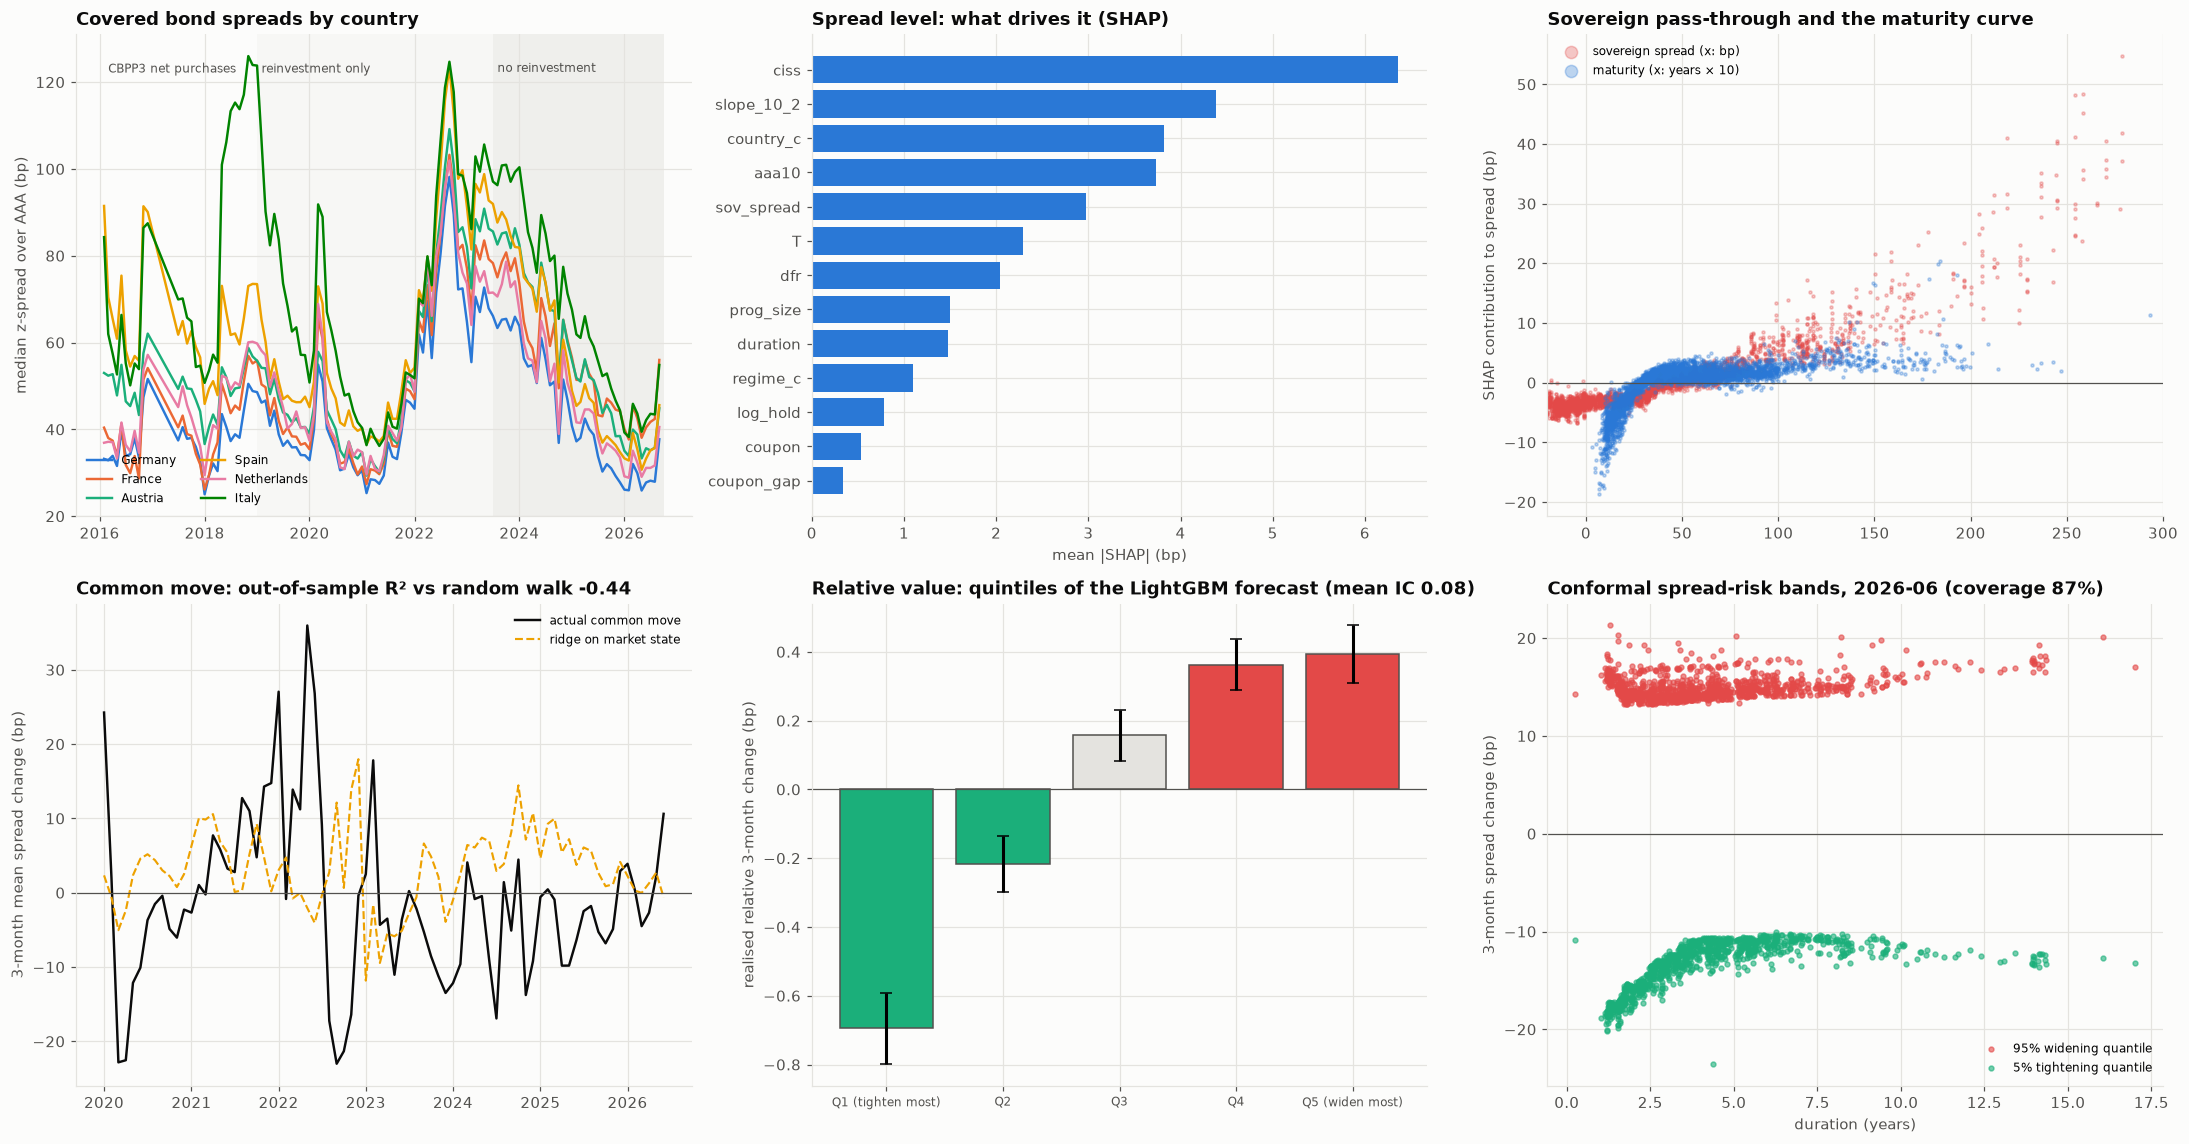

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10.5))
ax = axes[0, 0]
cols = dict(zip(top[:6], PALETTE))
for c in top[:6]:
    s = cty_m[c].dropna()
    ax.plot(s.index.to_timestamp(), s.values, lw=1.6, color=cols[c], label=c)
ax.axvspan(
    pd.Timestamp("2019-01-01"),
    pd.Timestamp("2023-07-01"),
    color=GRID,
    alpha=0.2,
    lw=0,
)
ax.axvspan(
    pd.Timestamp("2023-07-01"),
    pd.Timestamp("2026-10-01"),
    color=GRID,
    alpha=0.5,
    lw=0,
)
yt = ax.get_ylim()[1]
for x_, lab in [
    ("2016-03-01", "CBPP3 net purchases"),
    ("2019-02-01", "reinvestment only"),
    ("2023-08-01", "no reinvestment"),
]:
    ax.text(
        pd.Timestamp(x_), yt * 0.95, lab, fontsize=8, color=INK_2, va="top"
    )
ax.set_ylabel("median z-spread over AAA (bp)")
ax.set_title("Covered bond spreads by country")
ax.legend(fontsize=8, ncol=2, loc="lower left")
ax = axes[0, 1]
ax.barh(shap_imp.index[::-1], shap_imp.values[::-1], color=PALETTE[0])
ax.set_xlabel("mean |SHAP| (bp)")
ax.set_title("Spread level: what drives it (SHAP)")
ax = axes[0, 2]
i_s, i_t = FEAT.index("sov_spread"), FEAT.index("T")
ax.scatter(
    sample["sov_spread"],
    sv[:, i_s],
    s=4,
    alpha=0.3,
    color=PALETTE[7],
    label="sovereign spread (x: bp)",
)
ax.scatter(
    sample["T"] * 10,
    sv[:, i_t],
    s=4,
    alpha=0.3,
    color=PALETTE[0],
    label="maturity (x: years × 10)",
)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xlim(-20, 300)
ax.set_ylabel("SHAP contribution to spread (bp)")
ax.legend(fontsize=8, markerscale=4)
ax.set_title("Sovereign pass-through and the maturity curve")
ax = axes[1, 0]
ax.plot(
    cm.index.to_timestamp(),
    cm["common_fwd"],
    color=INK,
    lw=1.6,
    label="actual common move",
)
ax.plot(
    cm.index.to_timestamp(),
    cm["ridge"],
    color=PALETTE[3],
    lw=1.4,
    ls="--",
    label="ridge on market state",
)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_ylabel("3-month mean spread change (bp)")
ax.legend(fontsize=8)
ax.set_title(
    f"Common move: out-of-sample R² vs random walk {cm_tab.iloc[1, 1]:.2f}"
)
ax = axes[1, 1]
ax.bar(
    range(5),
    quint["mean"],
    color=[PALETTE[2], PALETTE[2], GRID, PALETTE[7], PALETTE[7]],
    edgecolor=INK_2,
    yerr=quint["std"] / np.sqrt(quint["size"]) * 1.96,
    capsize=4,
)
ax.set_xticks(range(5))
ax.set_xticklabels(quint.index, fontsize=8)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_ylabel("realised relative 3-month change (bp)")
ax.set_title(
    "Relative value: quintiles of the LightGBM forecast (mean IC"
    f" {rel_tab.iloc[1, 1]:.2f})"
)
ax = axes[1, 2]
last = qf[qf["m"] == qf["m"].max()]
ax.scatter(
    last["duration"],
    last["q95"],
    s=10,
    alpha=0.6,
    color=PALETTE[7],
    label="95% widening quantile",
)
ax.scatter(
    last["duration"],
    last["q5"],
    s=10,
    alpha=0.6,
    color=PALETTE[2],
    label="5% tightening quantile",
)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xlabel("duration (years)")
ax.set_ylabel("3-month spread change (bp)")
ax.set_title(
    f"Conformal spread-risk bands, {qf['m'].max()} (coverage"
    f" {qf['inside'].mean():.0%})"
)
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_covered_bond_spreads")
plt.show()

## 10. Reading the results and limitations

**History.**
- Covered bond spreads over the AAA curve moved in a narrow band while the ECB was buying. The median was around 30–60 bp, with Italy as the clear exception: its spread more than doubled in the 2018 sovereign scare, to about 125 bp.
- Spreads jumped across all countries with the 2022 rate shock, peaking near 100–125 bp in late 2022.
- They have since **tightened back to 30–55 bp despite the end of ECB reinvestments in July 2023**: the market absorbed record supply without the central-bank buyer.

**What explains the cross-section.**
- A LightGBM model, cross-validated by issuer (it never sees the issuer it prices), explains **86% of the variance** of spreads with a mean absolute error of 4 bp.
- The benchmarks do worse: 75% for "the country median of the month" and 55% for a linear country/regime/maturity model.
- SHAP ranks **market-wide stress (CISS), the slope and level of the AAA curve** first. Most of the variation in a ten-year panel is common to all bonds.
- Then come **country** and the **sovereign spread**, whose pass-through is visibly non-linear: almost nothing below 50 bp of sovereign spread, then roughly 15–20 bp of covered spread per 100 bp of sovereign spread.
- Next is **maturity**, with a steep curve below 3 years and nearly flat beyond 5.
- **Programme size** and coupon matter only at the margin.
- The issuer residuals are a ready-made relative-value screen: names whose spread is persistently wider than their characteristics imply (Monte dei Paschi, Danish Ship Finance, HSH/Hamburg Commercial) or tighter.

**Forecasting: the honest result.**
- **The market-wide move cannot be forecast.** A ridge regression on the changes in the market state does worse than a random walk out of sample: R² −0.44 over 2020–2026. Diebold–Mariano strongly favours the random walk. Quarterly spread moves are driven by news, and rate-regime shifts make any fitted relation unstable.
- **The relative move can, a little, and the simple model wins.** Mean reversion towards the country–maturity peer median has a positive information coefficient in 90% of months (mean IC 0.10, t ≈ 10).
- LightGBM's ranking is also informative: its quintiles are monotone, from −0.7 bp to +0.4 bp of relative change. But it is noisier (mean IC 0.08) and its point forecasts have a negative R².
- The effect is economically small, about 1 bp per quarter between extreme quintiles, against 5–6 bp of noise. That is useful for choosing between two similar bonds, not as a trading strategy after costs.

**Spread-risk bands.**
- Raw quantile forecasts badly under-cover: only 36% of outcomes fall inside the nominal 90% band.
- Conformal calibration on the preceding twelve months brings coverage to **87% overall**, and 84–100% in most years.
- The exception is **2022 (40%)**: when a regime changes, a band calibrated on the year before cannot know. That is the case for adding stress scenarios to statistical spread VaR, not replacing one with the other.

**Limitations.**
- The universe is that of one index-tracking ETF: liquid benchmark covered bonds, euro-denominated. Smaller and non-benchmark issues are missing.
- Bonds are identified by name, coupon and maturity because the file has no ISIN, and issuer names are not fully harmonised (renamings appear as separate issuers).
- Spreads are over the AAA government curve, not over swaps, so they mix credit, liquidity and the AAA–swap basis.
- Prices are the fund's month-end valuations, not executable quotes.

In [10]:
cty_m.to_csv(OUT_DIR / "median_spread_by_country_month.csv")
xs_tab.to_csv(OUT_DIR / "cross_section_model_scores.csv")
shap_imp.to_csv(
    OUT_DIR / "cross_section_shap_importance.csv", header=["mean_abs_shap_bp"]
)
iss_rich.to_csv(OUT_DIR / "issuer_residuals.csv")
cm_tab.to_csv(OUT_DIR / "common_move_forecast_scores.csv")
rel_tab.to_csv(OUT_DIR / "relative_value_forecast_scores.csv")
ic_year.to_csv(OUT_DIR / "information_coefficient_by_year.csv")
quint.to_csv(OUT_DIR / "forecast_quintile_sort.csv")
cov.to_csv(OUT_DIR / "quantile_band_coverage.csv")
d[[
    "m",
    "bond_id",
    "issuer",
    "country",
    "T",
    "coupon",
    "price",
    "z_bp",
    "peer_gap",
]].to_csv(OUT_DIR / "bond_month_spreads.csv.gz", index=False)
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_covered_bond_spreads.png, bond_month_spreads.csv.gz, common_move_forecast_scores.csv, cross_section_model_scores.csv, cross_section_shap_importance.csv, forecast_quintile_sort.csv, information_coefficient_by_year.csv, issuer_residuals.csv, median_spread_by_country_month.csv, quantile_band_coverage.csv, relative_value_forecast_scores.csv


## References

### Finance and regulation

- Prokopczuk, M., Siewert, J. B., & Vonhoff, V. (2013). Credit risk in covered bonds. *Journal of Empirical Finance, 21*, 102–120. https://doi.org/10.1016/j.jempfin.2012.12.003
- Packer, F., Stever, R., & Upper, C. (2007). The covered bond market. *BIS Quarterly Review*, September, 43–55. https://www.bis.org/publ/qtrpdf/r_qt0709f.htm
- Hollo, D., Kremer, M., & Lo Duca, M. (2012). *CISS – A composite indicator of systemic stress in the financial system* (ECB Working Paper No. 1426). European Central Bank. https://doi.org/10.2139/ssrn.2018792
- Svensson, L. E. O. (1994). *Estimating and interpreting forward interest rates: Sweden 1992–1994* (NBER Working Paper No. 4871). National Bureau of Economic Research. https://doi.org/10.3386/w4871
- Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics, 13*(3), 253–263. https://doi.org/10.1080/07350015.1995.10524599

### Machine learning and deep learning

- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*. https://arxiv.org/abs/1705.07874
- Romano, Y., Patterson, E., & Candès, E. (2019). Conformalized quantile regression. *Advances in Neural Information Processing Systems, 32*. https://arxiv.org/abs/1905.03222